# Setup

This notebook runs every test in the guide on real data. Short examples come first, to build intuition with
numbers small enough to check by hand; then each test is applied to a real question from climate, El Niño and the
monsoon, snow cover, and radar flood mapping. Every printed number is explained: what goes in, what comes out, its
units, and how to read it.

Libraries: **numpy** (arithmetic on arrays), **pandas** (tables), **scipy.stats** (the tests themselves) and
**matplotlib** (figures). A fixed random seed makes the simulations repeat exactly.

In [1]:
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data"); DATA.mkdir(exist_ok=True)
SOURCES = {
    "hadcrut5.csv": "https://www.metoffice.gov.uk/hadobs/hadcrut5/data/HadCRUT.5.0.2.0/analysis/diagnostics/"
                    "HadCRUT.5.0.2.0.analysis.summary_series.global.annual.csv",
    "oni.data": "https://psl.noaa.gov/data/correlation/oni.data",
    "indiamon.data": "https://psl.noaa.gov/data/correlation/indiamon.data",
    "nh_snow.txt": "https://climate.rutgers.edu/snowcover/files/moncov.nhland.txt",
    # a small table made for this guide from the radar manual's Sentinel-1 export (see data_local/SOURCE.txt)
    "sindh_sar_1km.csv": "https://raw.githubusercontent.com/AhmadAmmar/AhmadAmmar.github.io/main/guides/hypothesis-testing/notebooks/data_local/sindh_sar_1km.csv",
}
LOCAL = Path("data_local")                  # present when the notebook runs inside the guide's own folder
for name, url in SOURCES.items():
    if not (DATA / name).exists() and (LOCAL / name).exists():
        (DATA / name).write_bytes((LOCAL / name).read_bytes())
    if not (DATA / name).exists():
        req = urllib.request.Request(url, headers={"User-Agent": "hypothesis-notebook/1.0"})
        (DATA / name).write_bytes(urllib.request.urlopen(req, timeout=120).read())
    print(f"{name:14s} {(DATA / name).stat().st_size / 1e3:8.1f} kB")


def read_psl(path):
    """NOAA PSL index files: one row per year, twelve monthly values; -99.9 and -999.9 mean missing."""
    rows = []
    for line in Path(path).read_text().splitlines():
        parts = line.split()
        if len(parts) == 13 and parts[0].isdigit():
            rows.append([int(parts[0])] + [float(v) for v in parts[1:]])
    t = pd.DataFrame(rows, columns=["year", *range(1, 13)]).set_index("year")
    return t.mask(t <= -99)

hadcrut5.csv        7.0 kB
oni.data            6.7 kB
indiamon.data       3.5 kB
nh_snow.txt        13.3 kB
sindh_sar_1km.csv    755.1 kB


# A coin and a p-value

Every hypothesis test has the same shape. A **null hypothesis** (H₀) says "nothing special is going on". A **test
statistic** summarises the data in one number. Under H₀ that number has a known spread of values, its **sampling
distribution**. The **p-value** is the probability, if H₀ were true, of a statistic at least as extreme as the one
observed. A small p means the data would be surprising if H₀ were true.

Short example: a coin gives 60 heads in 100 flips. H₀: the coin is fair, P(heads) = 0.5. Statistic: the number of
heads. We find the p-value three ways: by simulating 100,000 fair coins, exactly from the binomial distribution, and
with the normal approximation (a z-score).

simulation p = 0.0571   exact binomial p = 0.0569
normal approximation: z = 2.00, p = 0.0455;  with continuity correction z = 1.90, p = 0.0574


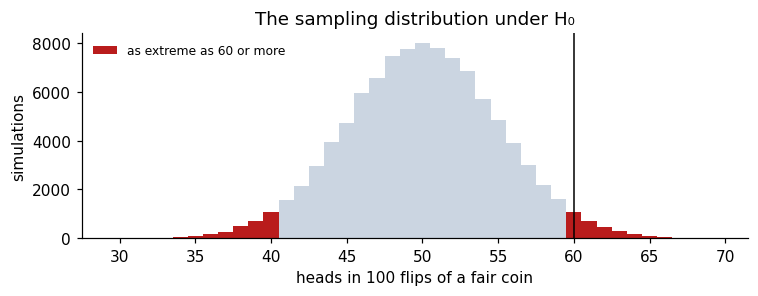

In [2]:
heads, n = 60, 100
sims = rng.binomial(n, 0.5, size=100_000)
p_sim = np.mean(np.abs(sims - 50) >= abs(heads - 50))            # two-sided: as far from 50 in either direction
p_exact = stats.binomtest(heads, n, 0.5).pvalue
z = (heads - n * 0.5) / np.sqrt(n * 0.5 * 0.5)                  # (observed - expected) / standard deviation
p_z = 2 * stats.norm.sf(abs(z))
z_cc = (abs(heads - n * 0.5) - 0.5) / np.sqrt(n * 0.5 * 0.5)     # continuity correction: counts are whole numbers
p_cc = 2 * stats.norm.sf(z_cc)
print(f"simulation p = {p_sim:.4f}   exact binomial p = {p_exact:.4f}")
print(f"normal approximation: z = {z:.2f}, p = {p_z:.4f};  with continuity correction z = {z_cc:.2f}, p = {p_cc:.4f}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(sims, bins=np.arange(30, 71) - 0.5, color="#cbd5e1")
ax.hist(sims[np.abs(sims - 50) >= 10], bins=np.arange(30, 71) - 0.5, color="#b91c1c", label="as extreme as 60 or more")
ax.axvline(60, color="k", lw=1)
ax.set(xlabel="heads in 100 flips of a fair coin", ylabel="simulations", title="The sampling distribution under H₀")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

Reading it: the grey histogram is what a fair coin produces; the red tails are results at least as far from 50 as
60 is. Their share, about 0.057, is the p-value. With the usual threshold **α = 0.05**, 0.057 is just above it, so
we would not reject H₀: 60 heads is a little unusual but not convincing evidence of a biased coin. The simulation
and the exact binomial agree. The plain normal approximation gives 0.046, which would wrongly fall below 0.05: it
treats the count of heads as continuous, while it can only be a whole number. The **continuity correction** subtracts
half a count from the distance to the expected value, and brings the approximation back to 0.057. Approximations are
convenient; when an exact test is available, use it, especially with small counts.

Two warnings that apply to every test below. A p-value is **not** the probability that H₀ is true, and a large
p-value does not show H₀ is true; it only says the data are not surprising under H₀. And a tiny p-value says nothing
about how big or important an effect is: for that we need an **effect size** and a **confidence interval**.

# The z-test: is one value unusual?

The **z-score** measures how many standard deviations (σ) a value lies from a mean (μ): z = (x − μ) / σ. If values
are normally distributed, about 95% fall within z = ±1.96, and the two-sided p-value is 2 × P(Z > |z|).

Short example, by hand: a class has a mean exam mark of 60 with σ = 10. A mark of 78 gives z = (78 − 60)/10 = 1.8,
and p = 2 × 0.036 = 0.072.

Real example: how unusual was 2024's global temperature compared with the climate of 1961–1990?

In [3]:
g = pd.read_csv(DATA / "hadcrut5.csv").rename(columns={"Time": "year", "Anomaly (deg C)": "anom"})[["year", "anom"]]
g = g[g.year <= 2024]
base = g[g.year.between(1961, 1990)].anom
mu, sigma = base.mean(), base.std(ddof=1)
x = g.loc[g.year == 2024, "anom"].iloc[0]
z = (x - mu) / sigma
print(f"1961-1990: mean μ = {mu:.3f} °C, standard deviation σ = {sigma:.3f} °C (n = {len(base)})")
print(f"2024: x = {x:.3f} °C  ->  z = ({x:.3f} - {mu:.3f}) / {sigma:.3f} = {z:.1f}")
print(f"two-sided p = {2 * stats.norm.sf(abs(z)):.1e}")
print(f"by hand, the class example: z = 1.8, p = {2 * stats.norm.sf(1.8):.3f}")

1961-1990: mean μ = 0.008 °C, standard deviation σ = 0.170 °C (n = 30)
2024: x = 1.181 °C  ->  z = (1.181 - 0.008) / 0.170 = 6.9
two-sided p = 5.5e-12
by hand, the class example: z = 1.8, p = 0.072


2024 lies about 7 standard deviations above the 1961–1990 mean, and the p-value is about 5 × 10⁻¹². Under the
climate of 1961–1990, a year this warm would essentially never happen. Units: z has none (it is a count of σ); μ, σ and x are
in °C. Caveat: the z-test assumes the reference years are independent draws from a normal distribution with a
stable mean; here the 1961–1990 years already contain a little trend, which makes σ slightly larger and the test
slightly conservative.

# The t-test for a trend

A trend's slope b is estimated from data, so it has a **standard error** SE(b). The **t-statistic** is
t = b / SE(b): how many standard errors the slope is from zero. Under H₀ (no trend) it follows a t distribution with
**degrees of freedom** df = n − 2 (n points, minus the two numbers fitted: slope and intercept). Degrees of freedom
count the independent pieces of information left after fitting; fewer means wider tails and larger p-values.

Short example, by hand: five years with slope b = 0.02 °C/yr and SE = 0.008 give t = 2.5, df = 3, and p = 0.088:
with so few points, even t = 2.5 is not strong evidence.

In [4]:
print(f"by hand: t = 0.02 / 0.008 = 2.5, df = 3, two-sided p = {2 * stats.t.sf(2.5, 3):.3f}")
w = g[g.year.between(1983, 2024)]
fit = stats.linregress(w.year, w.anom)
t_naive = fit.slope / fit.stderr
resid = w.anom - (fit.intercept + fit.slope * w.year)
r1 = np.corrcoef(resid[:-1], resid[1:])[0, 1]
n = len(w); n_eff = n * (1 - r1) / (1 + r1)
se_eff = fit.stderr * np.sqrt((n - 2) / (n_eff - 2))
t_eff = fit.slope / se_eff
print(f"global 1983-2024: b = {fit.slope * 10:.3f} °C/decade, SE = {fit.stderr * 10:.3f}, t = {t_naive:.1f}, df = {n - 2}, p = {fit.pvalue:.1e}")
print(f"lag-1 autocorrelation r1 = {r1:.2f} -> effective n = {n_eff:.1f}; corrected SE = {se_eff * 10:.3f}, t = {t_eff:.1f}, "
      f"df = {n_eff - 2:.1f}, p = {2 * stats.t.sf(t_eff, n_eff - 2):.1e}")
ci = fit.slope * 10 + np.array([-1, 1]) * stats.t.ppf(0.975, n_eff - 2) * se_eff * 10
print(f"95% confidence interval for the trend: {ci[0]:.3f} to {ci[1]:.3f} °C per decade")

by hand: t = 0.02 / 0.008 = 2.5, df = 3, two-sided p = 0.088
global 1983-2024: b = 0.216 °C/decade, SE = 0.013, t = 16.8, df = 40, p = 1.1e-19
lag-1 autocorrelation r1 = 0.22 -> effective n = 27.0; corrected SE = 0.016, t = 13.3, df = 25.0, p = 8.0e-13
95% confidence interval for the trend: 0.182 to 0.249 °C per decade


Reading it: the slope is about 0.22 °C per decade; t is about 17 (13 after allowing for autocorrelation) and p is
tiny, so a zero trend is ruled out.
The **confidence interval** is the more useful output: we are 95% confident the true trend lies between about 0.18
and 0.25 °C per decade. Allowing for autocorrelation (neighbouring years are alike, r₁ ≈ 0.2) reduces the 42 years to
about 27 independent ones and widens the interval, but here it changes nothing important. With weaker trends or
stronger autocorrelation it can turn a "significant" result into an insignificant one.

# Two groups: does El Niño weaken the Indian monsoon?

Question: is monsoon rainfall in central India lower in El Niño years than in La Niña years? Inputs: for each year
1950–1999, the June–September (JJAS) total of NOAA PSL's Central Indian precipitation index, and the JJAS mean of the
Oceanic Niño Index (ONI, °C anomaly of Pacific sea surface temperature). An El Niño year has ONI ≥ +0.5 °C, a La Niña
year ≤ −0.5 °C. We express rainfall as a percentage of its mean so the units are easy to read.

In [5]:
oni = read_psl(DATA / "oni.data")
rain = read_psl(DATA / "indiamon.data")
jjas = [6, 7, 8, 9]
m = pd.DataFrame({"oni": oni[jjas].mean(axis=1), "rain": rain[jjas].sum(axis=1, min_count=4)}).dropna()
m["rain_pct"] = 100 * m.rain / m.rain.mean()
m["phase"] = np.where(m.oni >= 0.5, "El Niño", np.where(m.oni <= -0.5, "La Niña", "neutral"))
print(m.groupby("phase").rain_pct.agg(["count", "mean", "std"]).round(1).to_string())
el, la = m.loc[m.phase == "El Niño", "rain_pct"], m.loc[m.phase == "La Niña", "rain_pct"]

         count   mean   std
phase                      
El Niño     10   86.0  13.2
La Niña     11  111.0  12.0
neutral     29  100.7  15.0


**Welch's t-test** compares two means without assuming the two groups have equal spread:
t = (x̄₁ − x̄₂) / √(s₁²/n₁ + s₂²/n₂), with degrees of freedom from the Welch–Satterthwaite formula. The
**Mann–Whitney U test** asks the same question using only the ranks of the values, so it does not assume normal
distributions and is not swayed by one extreme year. **Cohen's d** is the effect size: the difference in means
divided by the pooled standard deviation (about 0.2 small, 0.5 medium, 0.8 large).

El Niño mean 86.0% (n=10), La Niña mean 111.0% (n=11), difference -25.0 points
Welch t = -4.53, df = 18.3, p = 0.0003
Mann-Whitney U = 10, p = 0.0017
Cohen's d = -1.99
95% confidence interval for the difference: -36.6 to -13.4 percentage points


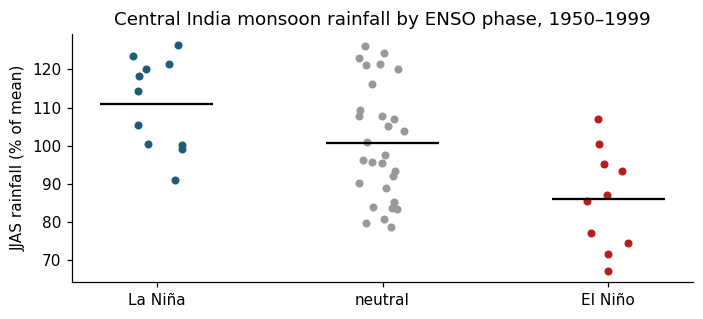

In [6]:
welch = stats.ttest_ind(el, la, equal_var=False)
mw = stats.mannwhitneyu(el, la, alternative="two-sided")
sp = np.sqrt(((len(el) - 1) * el.var() + (len(la) - 1) * la.var()) / (len(el) + len(la) - 2))
d = (el.mean() - la.mean()) / sp
print(f"El Niño mean {el.mean():.1f}% (n={len(el)}), La Niña mean {la.mean():.1f}% (n={len(la)}), difference {el.mean() - la.mean():.1f} points")
print(f"Welch t = {welch.statistic:.2f}, df = {welch.df:.1f}, p = {welch.pvalue:.4f}")
print(f"Mann-Whitney U = {mw.statistic:.0f}, p = {mw.pvalue:.4f}")
print(f"Cohen's d = {d:.2f}")
ci = welch.confidence_interval(0.95)
print(f"95% confidence interval for the difference: {ci.low:.1f} to {ci.high:.1f} percentage points")

fig, ax = plt.subplots(figsize=(6.5, 3))
for i, ph in enumerate(["La Niña", "neutral", "El Niño"]):
    v = m.loc[m.phase == ph, "rain_pct"]
    ax.scatter(np.full(len(v), i) + rng.uniform(-0.12, 0.12, len(v)), v, s=18, color=["#1f5c7a", "0.6", "#b91c1c"][i])
    ax.hlines(v.mean(), i - 0.25, i + 0.25, color="k")
ax.set_xticks([0, 1, 2], ["La Niña", "neutral", "El Niño"])
ax.set(ylabel="JJAS rainfall (% of mean)", title="Central India monsoon rainfall by ENSO phase, 1950–1999")
plt.tight_layout(); plt.show()

Reading it: each dot is one year; the black bars are group means. El Niño years average well below La Niña years.
The t-test and the rank test agree, the effect size is large, and the confidence interval for the difference excludes
zero. Limits: only 1950–1999 and one regional index; the relationship between ENSO and the monsoon is known to vary
between decades, and other influences (the Indian Ocean Dipole) are not included.

# Correlation: how strongly do ONI and rainfall move together?

**Pearson's r** measures linear association, from −1 to +1. To test H₀: r = 0, use t = r√(n − 2)/√(1 − r²) with
df = n − 2. **Spearman's ρ** is Pearson's r computed on ranks, so it captures any steady (monotonic) relation and
resists outliers. r² is the share of variance in one variable that a straight line on the other explains.

In [7]:
r, p = stats.pearsonr(m.oni, m.rain_pct)
n = len(m)
t_r = r * np.sqrt(n - 2) / np.sqrt(1 - r ** 2)
rho, p_rho = stats.spearmanr(m.oni, m.rain_pct)
print(f"Pearson r = {r:.2f}, n = {n}, t = {r:.2f} x sqrt({n - 2}) / sqrt(1 - {r:.2f}^2) = {t_r:.2f}, df = {n - 2}, p = {p:.1e}")
print(f"r squared = {r ** 2:.2f}: ONI accounts for {r ** 2:.0%} of the year-to-year variance in this index")
print(f"Spearman rho = {rho:.2f}, p = {p_rho:.1e}")
b = np.polyfit(m.oni, m.rain_pct, 1)
print(f"slope: {b[0]:.1f} percentage points of rainfall per +1 °C of ONI")

Pearson r = -0.43, n = 50, t = -0.43 x sqrt(48) / sqrt(1 - -0.43^2) = -3.26, df = 48, p = 2.0e-03
r squared = 0.18: ONI accounts for 18% of the year-to-year variance in this index
Spearman rho = -0.36, p = 1.0e-02
slope: -10.2 percentage points of rainfall per +1 °C of ONI


The correlation is negative (warmer central Pacific, drier central India), moderate in size (r ≈ −0.43) and
significant (p ≈ 0.002), but ONI explains only about a fifth of the variation (r² ≈ 0.18). The two-group comparison
above looked stronger because it compared only the extremes, El Niño against La Niña, leaving out the 29 neutral years. Correlation does not by itself show cause; here the physical mechanism (El Niño
shifts rising air over the Pacific and suppresses convection over India) is what makes the result meaningful.

# A trend test for snow: parametric and rank-based

Question: has June snow cover over Northern Hemisphere land declined since 1967? Data: Rutgers University Global Snow
Lab, monthly snow-covered area in km². We test the trend two ways. The OLS **t-test** for the slope (as above)
assumes normal, independent residuals. The **Mann–Kendall test** only asks whether later years tend to be lower than
earlier ones: it counts concordant and discordant pairs, which is Kendall's τ between year and value. It needs no
normality and is common for hydrological and snow series.

June snow cover, 1967-2025, n = 58
OLS slope = -1.19 million km² per decade, t = -9.9, p = 7.1e-14
Mann-Kendall (Kendall tau with year) tau = -0.61, p = 1.9e-11
residual lag-1 autocorrelation r1 = 0.06
first ten years mean 11.6, last ten years 6.5 million km² (-44%)


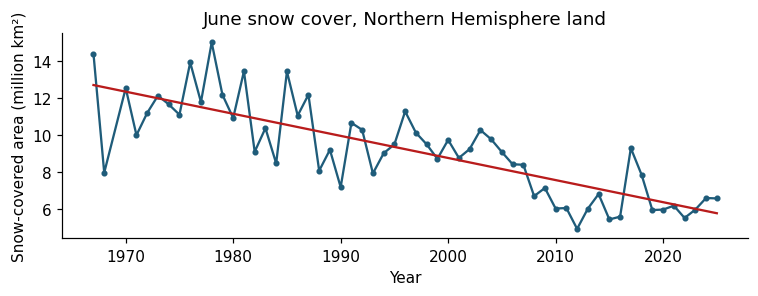

In [8]:
s = pd.read_csv(DATA / "nh_snow.txt", sep=r"\s+", header=None, names=["year", "month", "km2"])
june = s[(s.month == 6) & s.year.between(1967, 2025)].copy()
june["mkm2"] = june.km2 / 1e6
fit = stats.linregress(june.year, june.mkm2)
tau, p_mk = stats.kendalltau(june.year, june.mkm2)
resid = june.mkm2 - (fit.intercept + fit.slope * june.year)
r1 = np.corrcoef(resid[:-1], resid[1:])[0, 1]
print(f"June snow cover, {june.year.min()}-{june.year.max()}, n = {len(june)}")
print(f"OLS slope = {fit.slope * 10:.2f} million km² per decade, t = {fit.slope / fit.stderr:.1f}, p = {fit.pvalue:.1e}")
print(f"Mann-Kendall (Kendall tau with year) tau = {tau:.2f}, p = {p_mk:.1e}")
print(f"residual lag-1 autocorrelation r1 = {r1:.2f}")
first, last = june.mkm2.iloc[:10].mean(), june.mkm2.iloc[-10:].mean()
print(f"first ten years mean {first:.1f}, last ten years {last:.1f} million km² ({100 * (last / first - 1):.0f}%)")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(june.year, june.mkm2, "o-", ms=3, color="#1f5c7a")
ax.plot(june.year, fit.intercept + fit.slope * june.year, color="#b91c1c")
ax.set(xlabel="Year", ylabel="Snow-covered area (million km²)", title="June snow cover, Northern Hemisphere land")
plt.tight_layout(); plt.show()

Both tests reject "no trend" decisively: τ is strongly negative (most later years are lower than most earlier ones)
and the slope is about −1.2 million km² per decade, a 44% fall between the first and last ten years. The residuals
are barely autocorrelated (r₁ ≈ 0.06), so the ordinary t-test needs no correction here; always check before assuming. τ is unitless;
the slope is in million km² per decade.

# Counts in categories: chi-square on a radar flood map

The **chi-square (χ²) test of independence** asks whether two categorical variables are related. Observed counts O in
a table are compared with the counts E expected if the variables were independent (row total × column total / grand
total): χ² = Σ (O − E)² / E, with df = (rows − 1)(columns − 1). **Cramér's V** (0 to 1) is the effect size.

Question: in Sindh in September 2022, were radar-dark (likely flooded) 1 km cells more common where water had been
seen before? Data: mean Sentinel-1 VV backscatter in 2022 (dark means below −14.1 dB, the threshold used in the
radar manual) and the JRC Global Surface Water occurrence (any water seen since 1984, occurrence > 0).

In [9]:
sar = pd.read_csv(DATA / "sindh_sar_1km.csv")
sar["dark_2022"] = sar.vv_2022_db < -14.1
sar["water_before"] = sar.water_occurrence_pct > 0
obs = pd.crosstab(sar.water_before, sar.dark_2022)
chi2, p, dof, exp = stats.chi2_contingency(obs, correction=False)
V = np.sqrt(chi2 / (obs.values.sum() * (min(obs.shape) - 1)))
print("observed counts (rows: water seen before; columns: dark in 2022)")
print(obs.to_string())
print("\nexpected counts if independent")
print(pd.DataFrame(exp.round(0), index=obs.index, columns=obs.columns).to_string())
print(f"\nchi-square = {chi2:.0f}, df = {dof}, p = {p:.1e}, Cramér's V = {V:.2f}")

observed counts (rows: water seen before; columns: dark in 2022)
dark_2022     False  True 
water_before              
False         10002    594
True           6200   3484

expected counts if independent
dark_2022      False   True 
water_before                
False         8465.0  2131.0
True          7737.0  1947.0

chi-square = 2905, df = 1, p = 0.0e+00, Cramér's V = 0.38


Cells where water had been seen before were dark far more often than independence predicts, and p is vanishingly
small. But this test assumes every cell is an independent observation. Neighbouring cells of a flood are not
independent: one flooded field implies the next. With n = 20,280 the test is far too confident. One simple check is
to thin the grid, keeping only cells about 10 km apart, and test again.

In [10]:
thin = sar[(((sar.x_utm42n - sar.x_utm42n.min()) / 1000).round() % 10 == 0) & (((sar.y_utm42n - sar.y_utm42n.min()) / 1000).round() % 10 == 0)]
obs_t = pd.crosstab(thin.water_before, thin.dark_2022)
chi2_t, p_t, dof_t, _ = stats.chi2_contingency(obs_t, correction=False)
V_t = np.sqrt(chi2_t / (obs_t.values.sum() * (min(obs_t.shape) - 1)))
print(f"thinned to {len(thin)} cells about 10 km apart: chi-square = {chi2_t:.1f}, df = {dof_t}, p = {p_t:.1e}, Cramér's V = {V_t:.2f}")

thinned to 208 cells about 10 km apart: chi-square = 28.0, df = 1, p = 1.2e-07, Cramér's V = 0.37


With 1% of the cells, χ² falls roughly in proportion to n, but Cramér's V stays about the same: the strength of the
association does not depend on how many cells we count, while the p-value does. This is the general lesson: with very
large n, almost everything is "significant", so report the effect size and think about how many independent
observations you really have.

# Many tests at once: false discoveries

When a map is made by testing every pixel, some pixels will be "significant" by chance. With α = 0.05, about 5% of
pixels with no real change pass the test. The **Benjamini–Hochberg** procedure controls the **false discovery rate**
(FDR): among the results called significant, the expected share that are false is kept below a chosen q (say 5%).
Simulation: 1,000 pixels, of which 900 have no trend and 100 a real one.

In [11]:
n_null, n_real, years = 900, 100, np.arange(30)
pvals, truth = [], []
for i in range(n_null + n_real):
    slope = 0.0 if i < n_null else 0.04
    y = slope * years + rng.normal(0, 0.3, len(years))
    pvals.append(stats.linregress(years, y).pvalue); truth.append(i >= n_null)
pvals, truth = np.array(pvals), np.array(truth)
raw = pvals < 0.05
bh = stats.false_discovery_control(pvals, method="bh") < 0.05
for name, call in [("p < 0.05 for each pixel", raw), ("Benjamini-Hochberg, q = 0.05", bh)]:
    tp, fp = (call & truth).sum(), (call & ~truth).sum()
    print(f"{name:30s} called significant {call.sum():4d}: real {tp:3d}, false {fp:3d}, share false {fp / max(call.sum(), 1):.0%}")

p < 0.05 for each pixel        called significant  128: real 100, false  28, share false 22%
Benjamini-Hochberg, q = 0.05   called significant  105: real 100, false   5, share false 5%


Testing each pixel at 0.05 calls 28 no-change pixels significant, so more than a fifth of the "changes" are false.
Benjamini–Hochberg keeps the share of false discoveries near 5%. Here it still finds all 100 real trends because they
are strong; with weaker real effects it would miss some, which is the price of controlling false discoveries. On a real map with millions of pixels, this is the
difference between a map of change and a map of noise.

# Reading any test result

Every test reported in a paper should come with the same set of facts. This table collects the ones used above.

In [12]:
summary = pd.DataFrame([
    ["z-test", "Is one value unusual?", "a value, a mean, a known SD", "z = (x − μ)/σ", "none", "unitless (number of SDs)"],
    ["t-test for a slope", "Is there a trend?", "pairs (time, value)", "t = b / SE(b)", "n − 2 (fewer if autocorrelated)", "b in units of y per unit time"],
    ["Welch t-test", "Do two means differ?", "two samples", "t = (x̄₁ − x̄₂)/√(s₁²/n₁ + s₂²/n₂)", "Welch–Satterthwaite", "difference in units of y"],
    ["Mann–Whitney U", "Does one group tend to be larger?", "two samples", "U from ranks", "none", "U is a count of pairs"],
    ["Pearson r test", "Are two variables linearly related?", "pairs (x, y)", "t = r√(n−2)/√(1−r²)", "n − 2", "r unitless, −1 to 1"],
    ["Mann–Kendall", "Is there a monotonic trend?", "a time series", "Kendall τ of value with time", "none", "τ unitless, −1 to 1"],
    ["Chi-square", "Are two categories related?", "a table of counts", "χ² = Σ(O − E)²/E", "(rows − 1)(cols − 1)", "χ² unitless; Cramér's V 0 to 1"],
    ["Benjamini–Hochberg", "Which of many tests to believe?", "many p-values", "ranked p ≤ (k/m)·q", "none", "adjusted p-values"],
], columns=["test", "question", "inputs", "statistic", "degrees of freedom", "units"])
print(summary.to_string(index=False))

              test                            question                      inputs                          statistic              degrees of freedom                          units
            z-test               Is one value unusual? a value, a mean, a known SD                      z = (x − μ)/σ                            none       unitless (number of SDs)
t-test for a slope                   Is there a trend?         pairs (time, value)                      t = b / SE(b) n − 2 (fewer if autocorrelated)  b in units of y per unit time
      Welch t-test                Do two means differ?                 two samples t = (x̄₁ − x̄₂)/√(s₁²/n₁ + s₂²/n₂)             Welch–Satterthwaite       difference in units of y
    Mann–Whitney U   Does one group tend to be larger?                 two samples                       U from ranks                            none          U is a count of pairs
    Pearson r test Are two variables linearly related?                pairs (x, y)             